### Définitions

Apprentissage supervisé : la cible doit être connue pour tous les cas passés (sans cible, on cherche des groupes (K-means, CAH) : c'est le non supervisé).

| Étape | Ce que l'on fait | Exemple : le crédit
|---|---|---|
| 1. Poser la question | Choisir la cible à prédire et la décision qui en dépend | Ce client remboursera-t-il ? On accorde ou non le crédit | 
| 2. Préparer | Rassembler les données, corriger les erreurs, coder les catégories en nombres | Un fichier de 2 500 clients passés, sans valeur manquante |
| 3. Explorer | Regarder la cible et ses liens avec chaque variable| Le défaut monte avec l'endettement |
| 4. Découper | Mettre de côté une partie des cas pour le jugement final | 1 875 clients pour apprendre, 625 pour tester (75 -25 %)|
| 5. Apprendre et régler | Construire le modèle, choisir ses réglages par validation croisée | Un arbre de profondeur 6 |
| 6. Juger | Mesurer la qualité sur les cas mis de côté | Défauts détectés, fausses alertes |
| 7. Décider et suivre | Fixer la règle d'action, l'appliquer aux nouveaux cas, surveiller | Alerte au-delà de 20 % de risque |

Prédiction : on "juge" sur l'inconnu en apprenant du passé. Pour chaque nouveau cas on prédit avec une probabilité et des règles lisibles.    
L'apprentissage sur 75 % des données  - entraînement & validation - pour construire le modèle et ses règles  
On test ensuite sur le reste des données jamais vues (25 %) ➜ un peu comme si c'était de futures données. 

⇒ On tire les deux parties au hasard, en gardant la même part de défauts des deux côtés.  
Le test ne sert **qu'une seule fois**, si on s'en sert pour choisir les réglages, il ne mesure plus l'inconnu : le score annoncé sera trop optimiste.

**Attention** au surapprentissage (*Overfitting*) :  
- si bon sur les données d'apprentissage et bon score en test ➜ le modèle a appris les règles
- si très bon en apprentissage et moyen en test ➜ modèle a appris par coeur (surapprentissage)

|Famille|On prédit|Exemple|Arbre utilisé|
|---|---|---|---|
|Classification|Une catégorie|Défaut de paiement : oui ou non|Arbre de classification|
|Régression|Un nombre|Le montant d'un sinistre|Arbre de régression|

La cible a deux valeurs, défaut ou pas de défaut. L'arbre de régression suit la même logique, mais sa "feuille" donne une moyenne au lieu d'une catégorie.


#### Validation croisée à 5 plis (*5-fold cross-validation*)

L'apprentissage est découpé en 5 parts, et la note finale du réglage est la moyenne des 5 notes (validation sur chaque part)  
➜ on apprend sur 4 parts et on valide/note sur la 5e, sur 5 tours en passant à la part suivante (chaque observation sert 4 fois à apprendre et 1 fois à valider)

⇒ on garde le réglage qui a la meilleur moyenne

On découpe en plusieurs part (ici 5) pour qu'une note ne dépende pas du hasard de la coupe, avec 5 notes on voit une moyenne et les écarts entre elles.

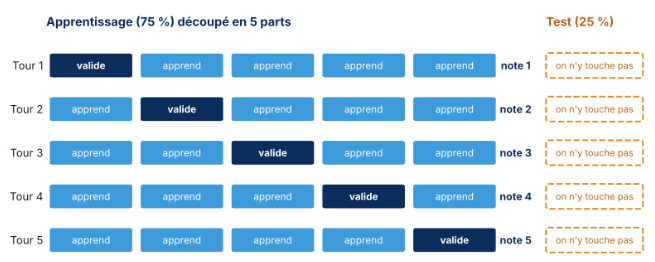

#### Vocabulaire et données

# A finir de relire + slide 8

En apprentissage supervisé, « défaut » désigne la variable cible à prédire : 
- `défaut = 1` : l'individu est en défaut (*ex. original du notebook* : le client ne rembourse pas son crédit)
- `défaut = 0` : l'individu ne présente pas de défaut  

VS  
Dans une classification binaire, le modèle estime la probabilité que l’observation appartienne à la classe « défaut ».  
Dans une régression, le terme peut simplement désigner une valeur attendue ou une erreur par rapport à cette valeur.  

Apprentissage non supervisé
Il n’y a pas de variable « défaut » connue à l’avance : l’algorithme découvre des structures dans les données.

On peut néanmoins définir a posteriori qu’un groupe ou un individu est considéré comme étant en « défaut », par exemple en interprétant un cluster regroupant des entreprises à risque. Cette interprétation dépend donc de l’analyse humaine.

Dans d’autres contextes
Erreur de prédiction : différence entre la valeur réelle et la valeur prédite ;
Anomalie : observation atypique, potentiellement considérée comme un défaut ;
Valeur par défaut : valeur de configuration utilisée lorsqu’aucune autre valeur n’est donnée ;
Stratégie de base : modèle toujours réutilisé quand aucune décision précise n’est prise.
Donc, en apprentissage supervisé, un défaut est généralement une classe ou étiquette connue ; en apprentissage non supervisé, c’est une anomalie ou catégorie interprétée après le regroupement des données.

| | Définition | Exemple |
|---|---|---|
|Observation | 1 cas / une ligne du tableau de données | un client |
|Variable explicative | une information connue sur chaque cas | le revenu, l'âge, l'emploi |
|Cible | le résultat que l'on veut prédire | défaut de paiement | oui ou non |
|Apprentissage | le modèle cherche des règles dans les cas passés | 1 875 clients dont on connaît le résultat |
|Modèle | l'ensemble des règles trouvées | un arbre de décision|
|Réglage| un choix fait avant l'apprentissage | la profondeur maximale de l'arbre|
|Prédiction | la réponse du modèle pour un nouveau cas | ce client risque un défaut : 70 %|

Une ligne par client, une colonne par information  
Les variables peuvent être des chiffres ou des catégories  
La cible à prédire : une colonne défaut à deux valeurs (bool. ou binaire)
Ni mise à l'échelle, ni standardisation : l'arbre compare des valeurs, il ne les additionne pas


les feuilles représentent les valeurs de la variable-cible et les embranchements correspondent à des combinaisons de variables d'entrée qui mènent à ces valeurs.

Une des variables d'entrée est sélectionnée à chaque nœud intérieur (ou interne, nœud qui n'est pas terminal) de l'arbre selon une méthode qui dépend de l'algorithme et qui sera discutée plus loin. Chaque arête vers un nœud-fils correspond à un ensemble de valeurs d'une variable d'entrée, de manière que l'ensemble des arêtes vers les nœuds-fils couvrent toutes les valeurs possibles de la variable d'entrée.

Chaque feuille (ou nœud terminal de l'arbre) représente soit une valeur de la variable-cible, soit une distribution de probabilité des diverses valeurs possibles de la variable-cible. La combinaison des valeurs des variables d'entrée est représentée par le chemin de la racine jusqu'à la feuille.

L'arbre est en général construit en séparant l'ensemble des données en sous-ensembles en fonction de la valeur d'une caractéristique d'entrée. Ce processus est répété sur chaque sous-ensemble obtenu de manière récursive, il s'agit donc d'un partitionnement récursif.

La récursion est achevée à un nœud soit lorsque tous les sous-ensembles ont la même valeur de la caractéristique-cible, ou lorsque la séparation n'améliore plus la prédiction. Ce processus est appelé induction descendante d'arbres de décision (top-down induction of decision trees ou TDIDT)[4], c'est un algorithme glouton puisqu'on recherche à chaque nœud de l'arbre le partage optimal, dans le but d'obtenir le meilleur partage possible sur l'ensemble de l'arbre de décision. C'est la stratégie la plus commune pour apprendre les arbres de décision depuis les données.

En fouille de données, les arbres de décision peuvent aider à la description, la catégorisation ou la généralisation d'un jeu de données fixé.

L'ensemble d'apprentissage est généralement fourni sous la forme d'enregistrements du type :

$(x, Y) = (x_1, x_2, x_3, \cdots, x_k, Y)$

La variable $Y$ désigne la variable-cible que l'on cherche à prédire, classer ou généraliser. Le vecteur $x$ est constitué des variables d'entrée $x_1, x_2, x_3$ etc. qui sont utilisées dans ce but.